# Hürlimann: how formula (2.2) works

Continuing from `hurlimann_2_1.ipynb`. Once the loss ratios $m_k$ of (2.1) are estimated, Hürlimann defines the **burning cost** of origin period $i$:

$$E\left[U_i^{BC}\right] = V_i \cdot \sum_{k=1}^{n} m_k \tag{2.2}$$

It is the expected total ultimate claims of origin period $i$: its premium times the loss ratio summed over **all** $n$ development periods. It is the same for every $i$ except for the scale $V_i$, and it ignores how much of origin period $i$ has already been paid. (The paper compares it to the Bornhuetter-Ferguson prior ultimate.)

Row $i$ of the *expected* triangle is $V_i \cdot m_k$ for $k = 1..n$, and (2.2) is that row summed across. It splits at the diagonal:

* $V_i \sum_{k=1}^{n-i+1} m_k$: expected paid to date (the part already observed, left of the diagonal),
* $V_i \sum_{k=n-i+2}^{n} m_k$: expected still to be paid (the part right of the diagonal). Formulas (2.3) and (2.4) turn this split into the payout factor $p_i$ and reserve factor $q_i$.

**Data are synthetic** (same invented triangle and seed as `hurlimann_2_1.ipynb`), not from the paper or an exam.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

n = 10
rng = np.random.default_rng(7)

# Synthetic inputs (assumed, same as the 2.1 notebook)
V = np.round(1000 * 1.05 ** np.arange(n))
m_true = np.array([.18, .20, .14, .09, .06, .04, .03, .02, .015, .01])
S_full = np.round(V[:, None] * m_true[None, :] * rng.normal(1, 0.08, (n, n)))
i_idx, k_idx = np.indices((n, n)) + 1
observed = i_idx + k_idx <= n + 1
S = np.where(observed, S_full, np.nan)

# Formula (2.1): loss ratios from the observed triangle
m = np.array([S[:n-k+1, k-1].sum() / V[:n-k+1].sum() for k in range(1, n + 1)])

# Formula (2.2): burning cost per origin period
total_lr = m.sum()
BC = V * total_lr

# Split at the diagonal
paid_exp = np.array([V[i-1] * m[:n-i+1].sum() for i in range(1, n + 1)])   # expected paid to date
rem_exp  = BC - paid_exp                                                    # expected remaining
paid_act = np.array([np.nansum(S[i-1]) for i in range(1, n + 1)])           # actual paid to date, C_{i,n-i+1}

pd.DataFrame({'V_i': V, 'sum of m_k': total_lr.round(4), 'E[U_i^BC]': BC.round(0),
              'expected paid': paid_exp.round(0), 'expected remaining': rem_exp.round(0),
              'actual paid C_i,n-i+1': paid_act},
             index=pd.Index(range(1, n + 1), name='i'))

,V_i,sum of m_k,E[U_i^BC],expected paid,expected remaining,"actual paid C_i,n-i+1"
i,,,,,,
1,1000.0,0.7623,762.0,762.0,0.0,777.0
2,1050.0,0.7623,800.0,790.0,10.0,815.0
3,1102.0,0.7623,840.0,815.0,26.0,782.0
4,1158.0,0.7623,883.0,833.0,50.0,805.0
5,1216.0,0.7623,927.0,841.0,86.0,853.0
6,1276.0,0.7623,973.0,834.0,139.0,850.0
7,1340.0,0.7623,1021.0,793.0,228.0,802.0
8,1407.0,0.7623,1073.0,710.0,362.0,693.0
9,1477.0,0.7623,1126.0,547.0,579.0,545.0


The loss ratio $\sum_k m_k$ is one number shared by all origin periods; only $V_i$ changes. The "expected paid" column is close to, but not equal to, the actual paid: $m_k$ is an average across origin periods, so individual diagonals deviate from it. That gap is what the individual (2.5) and collective (2.7) estimates later play off against each other.

## Picture: row $i$ of the expected triangle, summed

The top strip is $m_k$ for each $k$ (the output of 2.1). Each cell below it is $V_i \cdot m_k$. For a chosen $i$:

* **Blue** cells: $V_i m_k$ left of the diagonal (expected paid to date), $k \le n-i+1$.
* **Orange** cells: $V_i m_k$ right of the diagonal (expected remaining), $k > n-i+1$.
* All other rows are greyed. The right-hand number is $E[U_i^{BC}]$, the sum of the whole highlighted row.

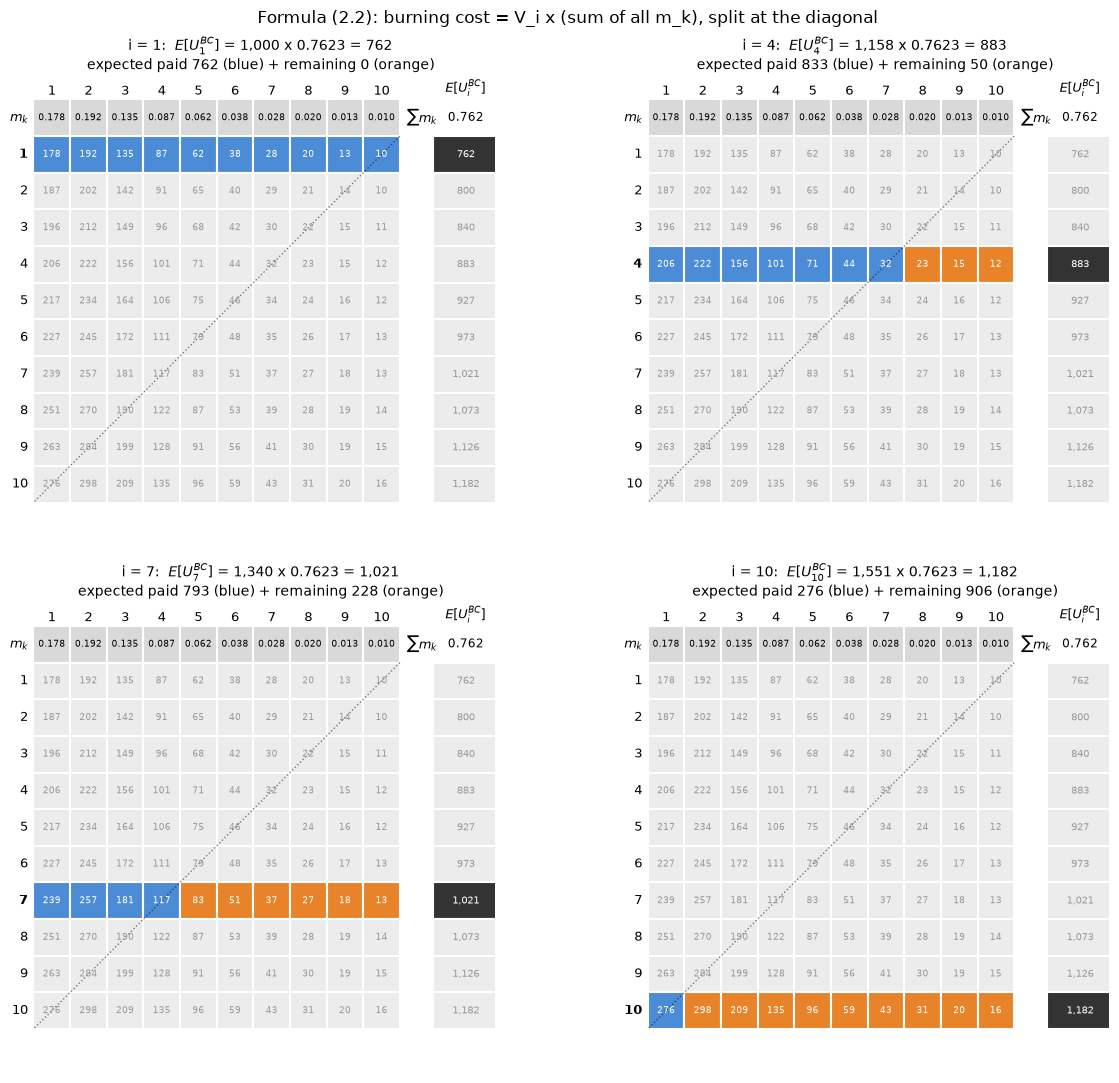

In [2]:
E = V[:, None] * m[None, :]          # expected incremental claims V_i * m_k, full 10x10

def draw(i, ax, annotate=True):
    last = n - i + 1                         # last observed development period for row i
    ax.set_xlim(-0.2, n + 2.6); ax.set_ylim(n + 1.2, -1.6)
    ax.set_aspect('equal'); ax.axis('off')

    # m_k strip on top (output of 2.1)
    ax.text(-.15, -.5, '$m_k$', ha='right', va='center', fontsize=9)
    for k in range(1, n + 1):
        ax.text(k - .5, -1.05, k, ha='center', va='bottom', fontsize=9)
        ax.add_patch(Rectangle((k - 1, -1), 1, 1, fc='#d9d9d9', ec='white', lw=1.5))
        if annotate:
            ax.text(k - .5, -.5, f'{m[k-1]:.3f}', ha='center', va='center', fontsize=6.5)
    ax.text(n + .6, -.5, '$\\sum m_k$', ha='center', va='center', fontsize=9)
    ax.text(n + 1.8, -.5, f'{total_lr:.3f}', ha='center', va='center', fontsize=8.5)
    ax.text(n + 1.8, -1.05, '$E[U^{BC}_i]$', ha='center', va='bottom', fontsize=9)

    for r in range(1, n + 1):
        sel = (r == i)
        ax.text(-.15, r - .5, r, ha='right', va='center', fontsize=9, fontweight='bold' if sel else 'normal')
        for k in range(1, n + 1):
            if not sel:
                fc, tc = '#ececec', '#999'
            elif k <= last:
                fc, tc = '#4c8bd6', 'white'
            else:
                fc, tc = '#e8832a', 'white'
            ax.add_patch(Rectangle((k - 1, r - 1), 1, 1, fc=fc, ec='white', lw=1.5))
            if annotate:
                ax.text(k - .5, r - .5, f'{E[r-1, k-1]:.0f}', ha='center', va='center', fontsize=6.5, color=tc)
        ax.add_patch(Rectangle((n + .9, r - 1), 1.8, 1, fc='#333' if sel else '#ececec', ec='white', lw=1.5))
        ax.text(n + 1.8, r - .5, f'{BC[r-1]:,.0f}', ha='center', va='center', fontsize=7.5,
                color='white' if sel else '#999')

    # diagonal marker
    ax.plot([n - .0, 0], [0, n], color='black', lw=1, ls=':', alpha=.5)
    ax.set_title(f'i = {i}:  $E[U^{{BC}}_{{{i}}}]$ = {V[i-1]:,.0f} x {total_lr:.4f} = {BC[i-1]:,.0f}\n'
                 f'expected paid {paid_exp[i-1]:,.0f} (blue) + remaining {rem_exp[i-1]:,.0f} (orange)', fontsize=10)

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, i in zip(axes.ravel(), [1, 4, 7, 10]):
    draw(i, ax)
fig.suptitle('Formula (2.2): burning cost = V_i x (sum of all m_k), split at the diagonal', fontsize=12)
plt.tight_layout(); plt.show()

### Reading the pictures

* **i = 1** (oldest year): the diagonal is at $k = 10$, so the whole row is blue. It is all expected-paid and nothing remains, so the burning cost equals the expected paid to date.
* **i = 4:** the first 7 development periods are blue, the last 3 orange.
* **i = 10** (newest year): only $k=1$ is blue. Almost the entire burning cost is still expected to be paid.
* The sum across the row is the same pattern ($\sum m_k$) for every $i$; the burning cost only scales with premium.

### All ten origin periods at a glance (cell values hidden)

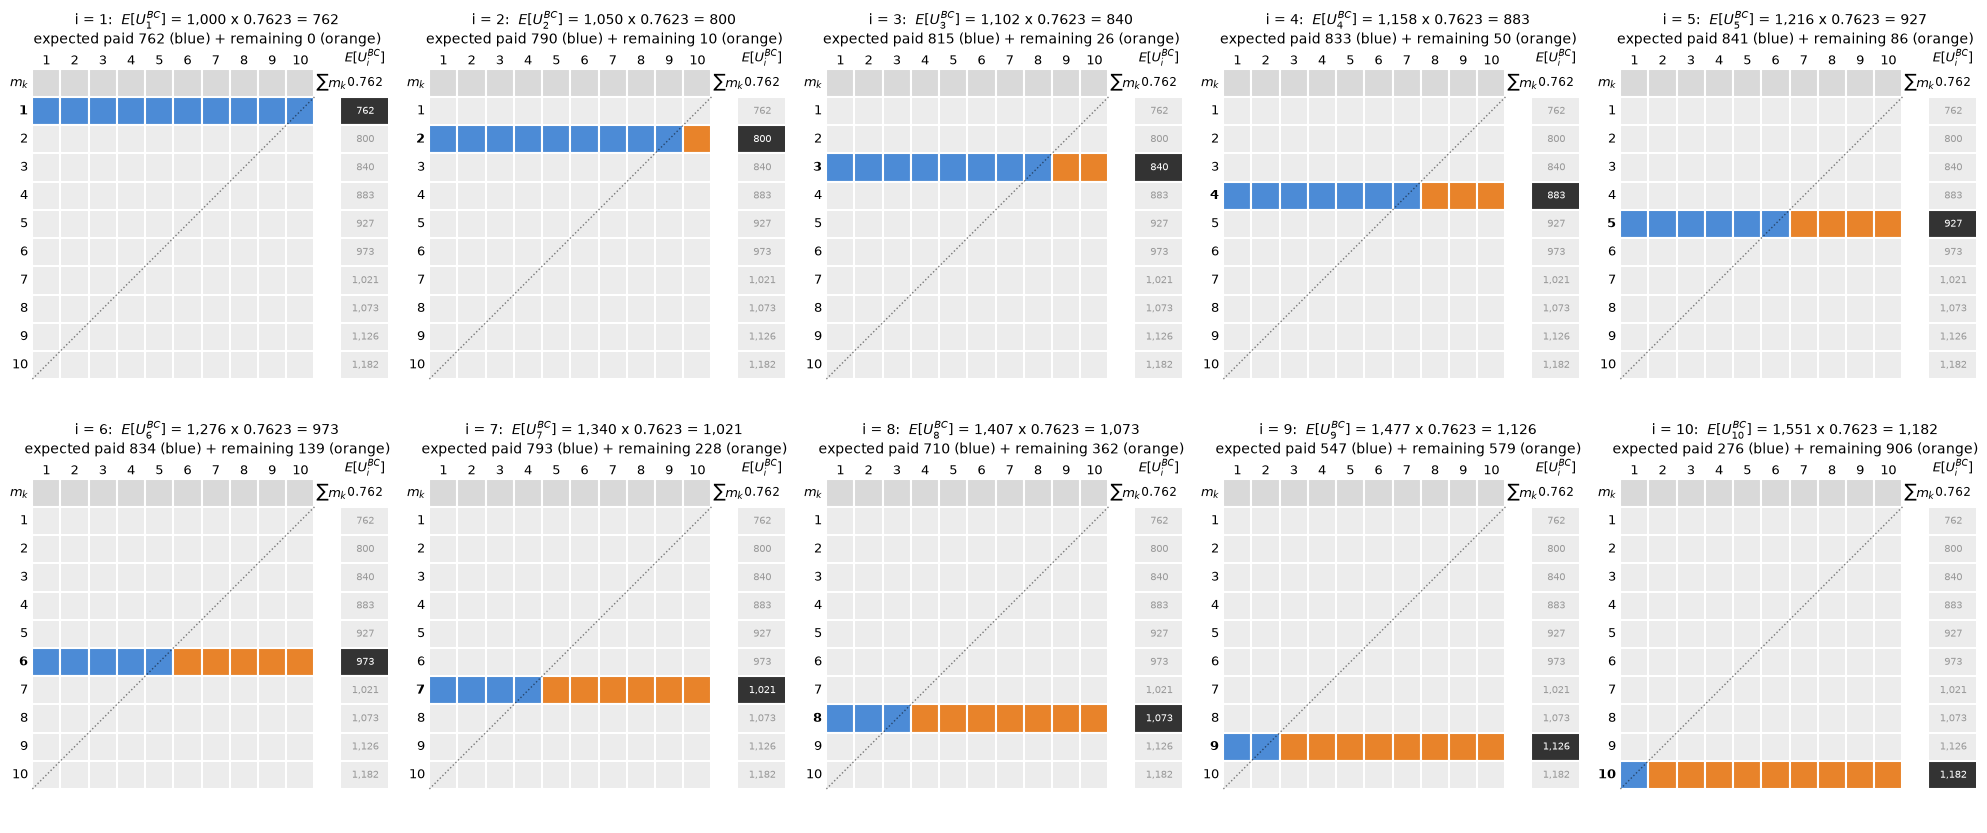

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8.5))
for ax, i in zip(axes.ravel(), range(1, n + 1)):
    draw(i, ax, annotate=False)
plt.tight_layout(); plt.show()

### Burning cost by origin period

Each bar is $E[U_i^{BC}]$ (premium times the same $\sum m_k$), split into expected paid to date and expected remaining. The marker shows actual paid to date. Dividing the blue part by the whole bar gives the payout factor $p_i$ of (2.3).

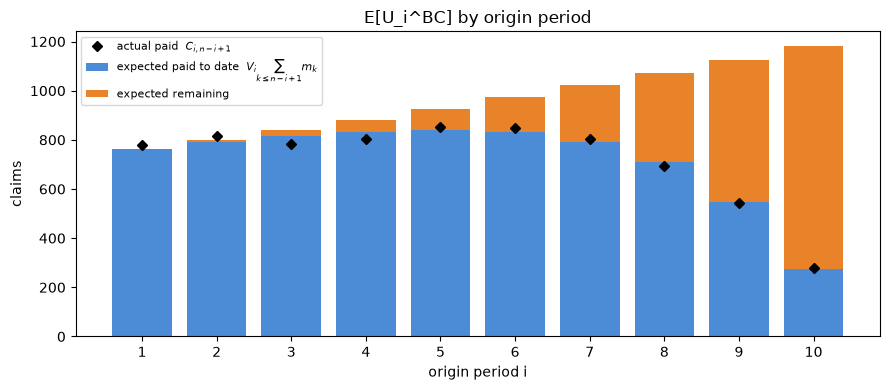

paid share  p_i = [1.    0.987 0.97  0.943 0.907 0.857 0.777 0.662 0.486 0.234]


In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(1, n + 1)
ax.bar(x, paid_exp, color='#4c8bd6', label='expected paid to date  $V_i\\sum_{k\\leq n-i+1} m_k$')
ax.bar(x, rem_exp, bottom=paid_exp, color='#e8832a', label='expected remaining')
ax.plot(x, paid_act, 'kD', ms=5, label='actual paid  $C_{i,n-i+1}$')
ax.set_xticks(x); ax.set_xlabel('origin period i'); ax.set_ylabel('claims')
ax.set_title('E[U_i^BC] by origin period'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('paid share  p_i =', np.round(paid_exp / BC, 3))